# Homework on Bass Model: Camp Snap
DS 223 Marketing Analytics (AUA) · Nvard Meliksetyan

This notebook runs the whole analysis step by step. It uses the same functions as the two scripts (`script1_estimate_parameters.py`, `script2_predict_diffusion.py`), so the numbers match the report in `report/report.pdf`.

Run it from the `HW1` folder (the one that contains `data/`).

## Step 1. The innovation
**Camp Snap**, a screen-free digital camera from TIME's Best Inventions of 2025: <https://time.com/collections/best-inventions-2025/7318270/camp-snap/>

It works like a disposable film camera but is digital: no screen, you see the photos only after downloading them. Launched in 2023, about US$65, more than 1 million cameras sold by early 2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from helper_functions import (bass_f, bass_F, bass_sales, load_series,
                              fit_bass_nls, fit_bass_ols, peak_time, adopter_categories)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## Step 2. Look-alike innovation: the digital camera
Camp Snap *is* a digital camera with the screen removed: same technology (sensor, memory card, USB), similar price range and buyers, and it spreads by word of mouth just like digital cameras did. So we use the digital camera's diffusion as the look-alike.

## Step 3. Historical data
Worldwide camera shipments by CIPA member companies, thousand units, 1951–2020 (CIPA data via Statista). We fit the Bass model on **1999–2020**, the digital-camera era; the earlier years are film cameras, a different generation.

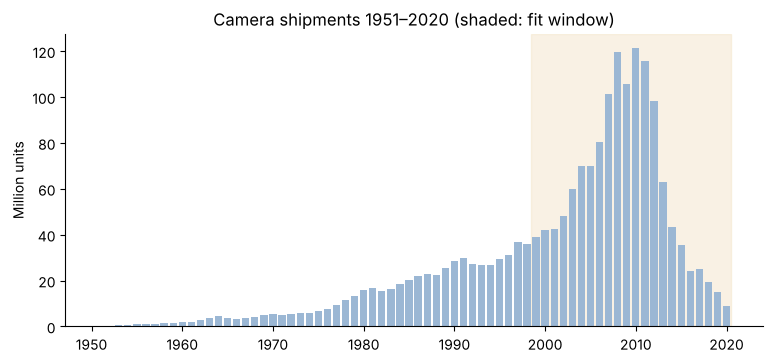

,year,sales
17,2016,24190
18,2017,24978
19,2018,19423
20,2019,15217
21,2020,8886


In [2]:
full = load_series("data/cameras_and_lenses.csv")
cam = load_series("data/cameras_and_lenses.csv", start_year=1999)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(full["year"], full["sales"] / 1000, color="#9bb7d4")
ax.axvspan(1998.5, 2020.5, color="#f2e2c4", alpha=.45, zorder=0)
ax.set_title("Camera shipments 1951–2020 (shaded: fit window)"); ax.set_ylabel("Million units")
plt.show()
cam.tail()

## Step 4. Estimating p, q and M for the look-alike
Two methods from the lecture:
1. **Non-linear least squares** on $a(t) = M f(t)$ (like R's `nls()`).
2. **Bass (1969) regression** $a(t)=\beta_0+\beta_1A(t-1)+\beta_2A(t-1)^2$, then $p=\beta_0/M$, $q=-M\beta_2$.

In [3]:
nls = fit_bass_nls(cam["sales"], p0=0.01, q0=0.3)
ols = fit_bass_ols(cam["sales"])
nls_full = fit_bass_nls(full["sales"], p0=0.002, q0=0.2)
res = pd.DataFrame([
    {"fit": "Cameras 1999-2020, NLS", "M (mln)": nls["m"]/1000, "p": nls["p"], "q": nls["q"], "R2": nls["r2"]},
    {"fit": "Cameras 1999-2020, OLS", "M (mln)": ols["m"]/1000, "p": ols["p"], "q": ols["q"], "R2": None},
    {"fit": "Cameras 1951-2020, NLS", "M (mln)": nls_full["m"]/1000, "p": nls_full["p"], "q": nls_full["q"], "R2": nls_full["r2"]},
])
res.round(4)

,fit,M (mln),p,q,R2
0,"Cameras 1999-2020, NLS",1374.6055,0.0106,0.3096,0.9089
1,"Cameras 1999-2020, OLS",1367.8819,0.0163,0.2951,NaN
2,"Cameras 1951-2020, NLS",1979.9808,0.0003,0.1064,0.6234


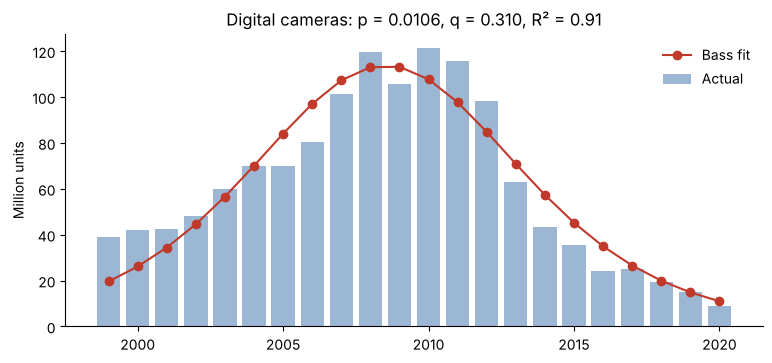

peak 10.5 years after 1998


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(cam["year"], cam["sales"] / 1000, color="#9bb7d4", label="Actual")
ax.plot(cam["year"], nls["fitted"] / 1000, color="#c0392b", marker="o", label="Bass fit")
ax.set_title(f"Digital cameras: p = {nls['p']:.4f}, q = {nls['q']:.3f}, R² = {nls['r2']:.2f}")
ax.set_ylabel("Million units"); ax.legend(frameon=False); plt.show()
p_analogue, q = nls["p"], nls["q"]
print("peak", round(peak_time(p_analogue, q), 1), "years after 1998")

The fit on the digital era is good (R² ≈ 0.91) and both methods agree. q is much bigger than p: digital cameras spread mainly by imitation. The full 1951–2020 fit is much worse because it mixes film and digital cameras.

## Step 6. Scope: United States
Camp Snap is a US company, about 90% of its sales come from its own US online store and the rest from US retailers (Target, REI, Best Buy), and its main use case is US summer camps that ban phones. So the forecast is for the US.

## Step 7a. Market potential M (Fermi estimate)
Every input, with its source or marked as an assumption, is in `data/fermi_inputs.csv`.

In [5]:
fermi = pd.read_csv("data/fermi_inputs.csv")
display(fermi)
f = fermi.set_index("input")["value"]
pop = f["US population (2024)"]
children = pop * f["Share of US population under 18"]
camp_kids = children * f["Share of US children who attend summer camp"]
parts = {
    "camp children": camp_kids * f["Camp children who eventually get a screen-free camera"],
    "other children": (children - camp_kids) * f["Other children who eventually get a screen-free camera"],
    "adults": (pop - children) * f["Adults who eventually buy one (nostalgia/travel/gifts)"],
}
for k, v in parts.items(): print(f"{k:15s} {v/1e6:5.1f} M")
M_base = round(sum(parts.values()) / 1e6) * 1e6
print(f"total           {sum(parts.values())/1e6:5.1f} M  -> M = {M_base/1e6:.0f} M")

,input,value,type,source
0,US population (2024),3.400000e+08,data,U.S. Census Bureau Vintage 2024 estimates (US ...
1,Share of US population under 18,2.150000e-01,data,"U.S. Census Bureau (2024), Under-18 population..."
2,Share of US children who attend summer camp,1.200000e-01,data,"American Camp Association, via Rustic Pathways..."
3,Camp children who eventually get a screen-free...,5.000000e-01,assumption,Own Fermi assumption (core segment; product wa...
4,Other children who eventually get a screen-fre...,7.500000e-02,assumption,Own Fermi assumption
5,Adults who eventually buy one (nostalgia/trave...,1.000000e-02,assumption,Own Fermi assumption
6,Camp Snap launch year,2.023000e+03,data,"Modern Retail (2026, Mar 9)"
7,Camp Snap cumulative cameras sold by early 2026,1.000000e+06,data,"Modern Retail (2026, Mar 9): more than 1 milli..."
8,Market potential M - low scenario,6.000000e+06,assumption,Half of the base Fermi estimate
9,Market potential M - high scenario,2.000000e+07,assumption,About 1.7x the base Fermi estimate


camp children     4.4 M
other children    4.8 M
adults            2.7 M
total            11.9 M  -> M = 12 M


## Step 5. Predicting Camp Snap's diffusion
- **q** is taken from the digital camera (word of mouth works the same way).
- **p**: two scenarios.
  - **A**: the digital camera's p unchanged.
  - **B** (main forecast): p chosen so the model gives exactly the 1 million cameras Camp Snap sold by the end of 2025 (t = 3).

In [6]:
LAUNCH, OBS_T, OBS_CUM = 2023, 3, f["Camp Snap cumulative cameras sold by early 2026"]
def calibrate_p(M):
    return brentq(lambda p: bass_F(OBS_T, p, q) - OBS_CUM / M, 1e-5, 0.9)

p_B = calibrate_p(M_base)
check = pd.DataFrame({
    "scenario": ["A: look-alike p", "B: calibrated p"],
    "p": [p_analogue, p_B],
    "model cumulative by end-2025": [M_base * bass_F(OBS_T, p_analogue, q), M_base * bass_F(OBS_T, p_B, q)],
    "actual": [OBS_CUM, OBS_CUM]})
check.round(4)

,scenario,p,model cumulative by end-2025,actual
0,A: look-alike p,0.0106,610129.4747,1000000.0
1,B: calibrated p,0.0178,1000000.0000,1000000.0


Scenario A predicts only about 0.61 million cameras by the end of 2025, while Camp Snap actually sold more than 1 million, so with the look-alike p unchanged the model is too slow. Scenario B fixes this with p = 0.0178, which is still close to the look-alike's two estimates (0.0106 and 0.0163).

## Step 7b. Adopters by period
New adopters in year t are $M[F(t) - F(t-1)]$. Low and high scenarios use M = 6M and M = 20M, with p re-calibrated each time.

In [7]:
years = np.arange(LAUNCH, LAUNCH + 18); t = years - LAUNCH + 1
rows, table = [], pd.DataFrame({"year": years})
for tag, M in {"low": f["Market potential M - low scenario"], "base": M_base,
               "high": f["Market potential M - high scenario"]}.items():
    p = calibrate_p(M)
    table[f"new_{tag}"] = (M * (bass_F(t, p, q) - bass_F(t - 1, p, q))).round().astype(int)
    table[f"cum_{tag}"] = (M * bass_F(t, p, q)).round().astype(int)
    cats = adopter_categories(p, q)
    rows.append({"scenario": tag, "M": M, "p": round(p, 4), "peak year": round(LAUNCH - 1 + peak_time(p, q), 1),
                 "early majority from": round(LAUNCH - 1 + cats["t1_early_majority_starts"], 1),
                 "laggards from": round(LAUNCH - 1 + cats["t2_laggards_start"], 1)})
display(pd.DataFrame(rows))
table[["year", "new_base", "cum_base", "new_low", "new_high"]]

,scenario,M,p,peak year,early majority from,laggards from
0,low,6000000.0,0.0379,2028.0,2024.3,2031.8
1,base,12000000.0,0.0178,2030.7,2026.7,2034.7
2,high,20000000.0,0.0104,2032.6,2028.5,2036.7


,year,new_base,cum_base,new_low,new_high
0,2023,247755,247755,259795,243295
1,2024,327263,575018,331493,325539
2,2025,424982,1000000,408713,431165
3,2026,539828,1539828,483129,563412
4,2027,666801,2206629,543449,723387
5,2028,795766,3002395,578214,908097
6,2029,911571,3913966,579898,1108276
7,2030,996510,4910476,548119,1306966
8,2031,1035178,5945654,489812,1480346
9,2032,1019887,6965541,416241,1602040


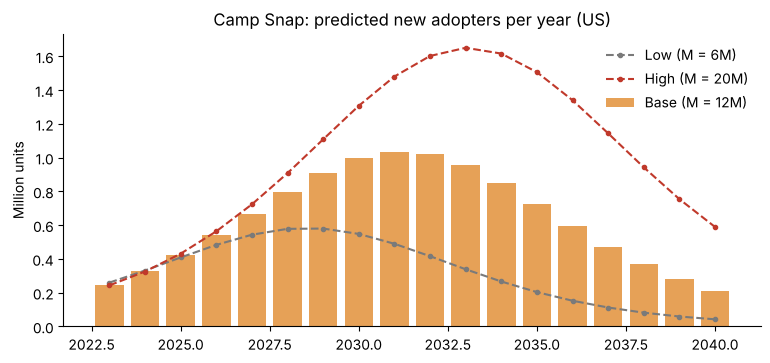

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(years, table["new_base"] / 1e6, color="#e6a157", label="Base (M = 12M)")
ax.plot(years, table["new_low"] / 1e6, "--.", color="#7a7a7a", label="Low (M = 6M)")
ax.plot(years, table["new_high"] / 1e6, "--.", color="#c0392b", label="High (M = 20M)")
ax.set_title("Camp Snap: predicted new adopters per year (US)"); ax.set_ylabel("Million units")
ax.legend(frameon=False); plt.show()

**Result.** In the base case Camp Snap sales keep growing until a peak of about **1.0 million cameras in 2031**, and half the US market (about 6 million) is reached around 2031–2032. A smaller market (low case) means an earlier, lower peak (2028); a larger one (high case) pushes the peak to 2033.

**Keep in mind:** M depends on my own Fermi assumptions; units sold are not exactly people; and the model does not include price changes or competitors such as the Kodak Charmera.